# Compare results across assays

This notebook calculates:
- Overlap of alleles and genes with results across three measured assays
- Distribution of ClinVar categories across three assays
- Comparison of actual readouts across assays
- Comparison of measured assays to the AI scores
- Comparison of assay readouts to the sequence features (plDDT and RSA)

In [1]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib_venn import venn3
import numpy as np 
import matplotlib.colors as colors
from venn import venn

In [2]:
inputs_dir = "../1_inputs"
outputs_dir = "../3_outputs"
metadata_outputs = "../../1_allele_collection/3_outputs"

## Process assay results

In [8]:
## imaging data
imaging = pl.read_csv(f"{inputs_dir}/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000)
## dualipa data
abun = pl.read_csv(f"{inputs_dir}/annotated_perturbation_scores.csv", infer_schema_length=10000).with_columns(
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
)
## ppi data
ppi = pl.read_csv(f"{inputs_dir}/ppi_scores.csv").select(["orf_id", "mut_id", "normalized_euclid_distance"]).unique().rename({
    "normalized_euclid_distance": "ppi_score"
})
## all scores
ai = pl.read_csv(f"{inputs_dir}/varchamp_clinvar_gnomad_dbnsfp_disease_modules.tsv", separator="\t", infer_schema_length=10000)
# .with_columns(
#     pl.concat_str(["symbol", "aa_change"], separator="_").alias("allele_0")
# )

In [19]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs}/varchamp_consolidated_alleles_clinvar_gnomad_sequence_confirmed.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("gene_allele")
)

In [9]:
ai

symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,dualip_ref_sequence_confirmation_class,mislocalization_sequenced,mislocalization_sequence_confirmation_class,mislocalization_ref_sequence_confirmation_class,gene_variant,…,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,gene_allele,RSA_Category,pLDDT_Category
str,str,i64,f64,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,…,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str,str
"""GBA1""","""ENSG00000177628""",2,6.0,"""CCSBVarC000001""","""ALE0000584""","""NC_000001.11:155240033:C:G""","""160G>C""","""Val54Leu""","""RC4""","""RC4_Mut_GDEh1026""","""H01""","""GDEhDisVCh_40054""","""F12""",2.0,"""RC4_Mut_GDDh1026""","""H01""",null,null,null,null,null,null,1.0,1.0,1.0,2.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Val54Leu""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0,null,null,null,"""GBA1_Val54Leu""","""10-90""",""">90"""
"""GBA1""","""ENSG00000177628""",2,73.0,"""CCSBVarC000002""","""ALE00000002""","""NC_000001.11:155238225:G:A""","""670C>T""","""Leu224Phe""","""RC4""","""RC4_Mut_GDEh1026""","""E01""","""GDEhDisVCh_40054""","""C12""",2.0,"""RC4_Mut_GDDh1026""","""E01""",null,null,null,null,null,null,1.0,1.0,1.0,1.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Leu224Phe""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0,null,null,null,"""GBA1_Leu224Phe""","""10-90""",""">90"""
"""GBA1""","""ENSG00000177628""",2,113.0,"""CCSBVarC000003""","""ALE00000003""","""NC_000001.11:155237453:C:T""","""887G>A""","""Arg296Gln""","""RC4""","""RC4_Mut_GDEh1026""","""F01""","""GDEhDisVCh_40054""","""D12""",2.0,"""RC4_Mut_GDDh1026""","""F01""",null,null,null,null,null,null,1.0,1.0,1.0,7.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Arg296Gln""",…,"""1q22""","""criteria provided, multiple su…",15.0,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3.0,4328.0,1.55237453e8,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2.0,"""1_Pathogenic""",98.91,0.225806,"""['608013', '230800', '230900',…","""multiple""",null,0,"""GAUCHER DISEASE, PERINATAL LET…",98.91,0.225806,"""GBA1_Arg296Gln""","""10-90""",""">90"""
"""GBA1""","""ENSG00000177628""",2,231.0,"""CCSBVarC000004""","""ALE00000004""","""NC_000001.11:155235252:A:G""","""1448T>C""","""Leu483Pro""","""RC4""","""RC4_Mut_GDEh1026""","""G01"""

In [25]:
abun

symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,valid_well,median_gfp,median_mcherry,median_GFP_mCherry_ratio,wt_GFP_mCherry_ratio_median,allele_wt_ratio_median,zscore_median,zcat_median,zscore_log2,symbol_right,aa_change_right,nt_change_right,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
str,str,str,str,i64,str,str,i64,i64,i64,bool,f64,f64,f64,f64,f64,f64,i64,f64,str,str,str,str,str,str,f64,f64,str
"""IL36RN""","""allele""","""368C>G""","""Thr123Arg""",3,"""C09""","""3_C09""",9149,8151,202847,true,32.760002,3332.0,0.008973,null,null,null,0,null,"""IL36RN""","""Thr123Arg""","""368C>G""","""ENSG00000136695""","""CEGS2""","""1_Pathogenic""",6.8417e-7,null,"""IL36RN_Thr123Arg"""
"""MLH1""","""allele""","""116G>T""","""Cys39Phe""",18,"""H02""","""18_H02""",8459,2713,473,true,46.5,5552.399902,0.008741,null,null,null,0,null,"""MLH1""","""Cys39Phe""","""116G>T""","""ENSG00000076242""","""Edgotyping3""","""4_VUS""",null,3.0,"""MLH1_Cys39Phe"""
"""KCNJ2""","""allele""","""821A>T""","""Asp274Val""",11,"""H06""","""11_H06""",4976,100016069,2638,true,897.920013,2918.650024,0.253414,0.841771,0.301048,-2.161051,-2,-3.794758,"""KCNJ2""","""Asp274Val""","""821A>T""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",6.8405e-7,1.0,"""KCNJ2_Asp274Val"""
"""PLP1""","""allele""","""128C>T""","""Thr43Ile""",9,"""B11""","""9_B11""",9258,4062,201422,true,126.040001,5390.349854,0.024643,null,null,null,0,null,"""PLP1""","""Thr43Ile""","""128C>T""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,1.0,"""PLP1_Thr43Ile"""
"""PKP2""","""allele""","""1415A>G""","""Lys472Arg""",19,"""F05""","""19_F05""",2900,54308,3072,true,718.52002,912.559998,0.674567,0.629182,1.072134,0.052776,0,0.208688,"""PKP2""","""Lys472Arg""","""1415A>G""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Lys472Arg"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ALAS2""","""allele""","""1591A>G""","""Ser531Gly""",4,"""G10""","""4_G10""",10913,8420,216668,true,583.309998,3528.0,0.162274,0.150224,1.080211,0.075965,0,0.232344,"""ALAS2""","""Ser531Gly""","""1591A>G""","""ENSG00000158578""","""CEGS2""","""1_Pathogenic""",null,null,"""ALAS2_Ser531Gly"""
"""STXBP1""","""allele""","""1217G>A""","""Arg406His""",13,"""A09""","""13_A09""",4229,7652,1827,true,270.630005,1189.299927,0.183448,1.265654,0.144943,-2.609238,-2,-6.09864,"""STXBP1""","""Arg406His""","""1217G>A""","""ENSG00000136854""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""STXBP1_Arg406His"""
"""POMT1""","""allele""","""1704G>C""","""Gln568His""",14,"""D02""","""14_D02""",9023,71206,205722,false,61.380001,5108.600098,0.013358,null,null,null,0,null,"""POMT1""","""Gln568His""","""1704G>C""","""ENSG00000130714""","""CEGS2""","""3_Conflicting""",0.000001,1.0,"""POMT1_Gln568His"""


In [10]:
ppi

orf_id,mut_id,ppi_score
i64,i64,f64
71892,4004,0.377595
100016069,2659,0.662913
888,200363,0.875
54308,3133,0.119678
11805,2156,0.0625
…,…,…
8151,202848,0.080687
2713,1005,0.685366
71337,3950,0.502597


In [11]:
imaging

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,…,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,i64,f64,str,…,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str
"""MLH1""","""MLH1_Asp485Glu""",-3.702836,0.026878,2.205143,0.081723,"""2024_12_Batch_11-12""",true,true,false,true,false,false,false,false,false,false,0.865471,0.906529,0.830224,0.90577,0.92833,0.931215,0.911098,0.826742,0.90995,0.853856,0.925446,0.900441,0.833706,0.903108,0.877086,"""MLH1""","""ENSG00000076242""",2713,200868.0,"""CCSBVarC003206""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Rare genetic immune disease; R…",3,null,null,null,"""10-90""",""">90"""
"""STXBP1""","""STXBP1_Asp238Glu""",0.220206,0.83589,-0.594736,0.576362,"""2024_12_Batch_11-12""",true,true,false,true,true,false,false,false,true,false,0.962583,0.967856,0.94548,0.981813,0.9731,0.978691,0.990391,0.966244,0.971952,0.977342,0.967508,0.973234,0.924715,0.96376,0.947824,"""STXBP1""","""ENSG00000136854""",7652,1806.0,"""CCSBVarC007627""",…,1.27666216e8,"""9q34.11""","""criteria provided, single subm…",1.0,"""-""","""N""","""ClinGen:CA173644""",2.0,160074.0,1.27666216e8,"""C""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000195171""","""-""","""-""","""714C>A ""","""Asp238Glu""","""NM_001032221.6""",1.0,"""4_VUS""",97.03,0.0,"""['612164']""","""multiple""","""Rare genetic developmental def…",5,"""DEVELOPMENTAL AND EPILEPTIC EN…",97.03,0.0,"""<10""",""">90"""
"""HPRT1""","""HPRT1_Asp177Tyr""",-1.597424,0.154203,-5.605154,0.000812,"""2024_01_Batch_7-8""",true,false,false,false,false,false,false,false,false,false,0.953241,0.866082,0.899639,0.846158,0.651201,0.765955,0.798049,0.893909,0.827773,0.948173,0.536447,0.894266,0.905369,0.90439,0.958309,"""HPRT1""","""ENSG00000165704""",7982,202804.0,"""CCSBVarC005941""",…,1.34498433e8,"""Xq26.2""","""no assertion criteria provided""",1.0,"""-""","""N""","""ClinGen:CA255001,UniProtKB:P00…",1.0,10049.0,1.34498433e8,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000030975""","""-""","""-""","""529G>T ""","""Asp177Tyr""","""NM_000194.3""",null,"""1_Pathogenic""",98.1,0.171779,"""['300

In [28]:
# merge all scores
scores = metadata.join(abun, on=["orf_id", "mut_id"], how="left", suffix="_abun")
scores = scores.join(imaging, on="gene_allele", how="left")
scores = scores.join(ppi, on=["orf_id", "mut_id"], how="left", suffix="_ppi")
scores = scores.join(ai, on="gene_allele", how="left")

# Get rid of duplicates
scores = scores.drop(["orf_id", "mut_id"])
scores = scores.unique()

# Keep only alleles with at least one score
scores = scores.filter(
    ~(pl.col("zscore_log2").is_null() & pl.col("ppi_score").is_null())
)
scores.select(["symbol", "aa_change"]).unique().shape

(984, 2)

## Calculate overlaps across assays

We profiled this many alleles in each assay: 790 for abundance, 755 for mislocalization, 426 for ppi, and 853 for AI.


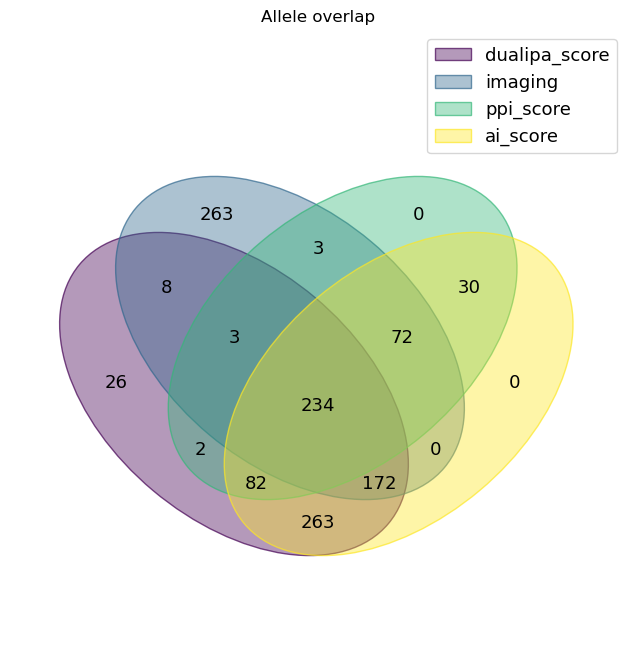

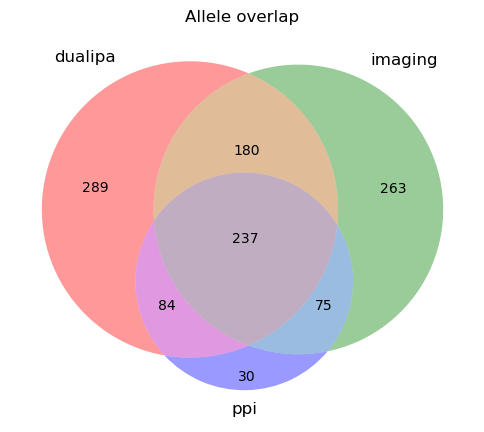

In [37]:
# Check overlap between three assays

set_abun = set(scores.filter(pl.col("zscore_log2").is_not_null()).select("allele_0").to_series())
set_misloc = set(imaging.select("gene_allele").to_series())
set_ppi = set(scores.filter(pl.col("ppi_score").is_not_null()).select("allele_0").to_series())
set_ai = set(scores.filter(pl.col("ai_score").is_not_null()).select("allele_0").to_series())
sets = {
    "dualipa_score": set_abun,
    "imaging": set_misloc,
    "ppi_score": set_ppi,
    "ai_score": set_ai
}

print(f"We profiled this many alleles in each assay: {len(set_abun)} for abundance, {len(set_misloc)} for mislocalization, {len(set_ppi)} for ppi, and {len(set_ai)} for AI.")

venn(sets)
plt.title("Allele overlap")
plt.show()

plt.figure(figsize=(6, 6))
venn3([set_abun, set_misloc, set_ppi], ('dualipa', 'imaging', 'ppi'))
plt.title("Allele overlap")
plt.show()

We profiled this many genes in each assay: 92 for abundance, 124 for mislocalization, 81 for ppi, and 121 for AI.


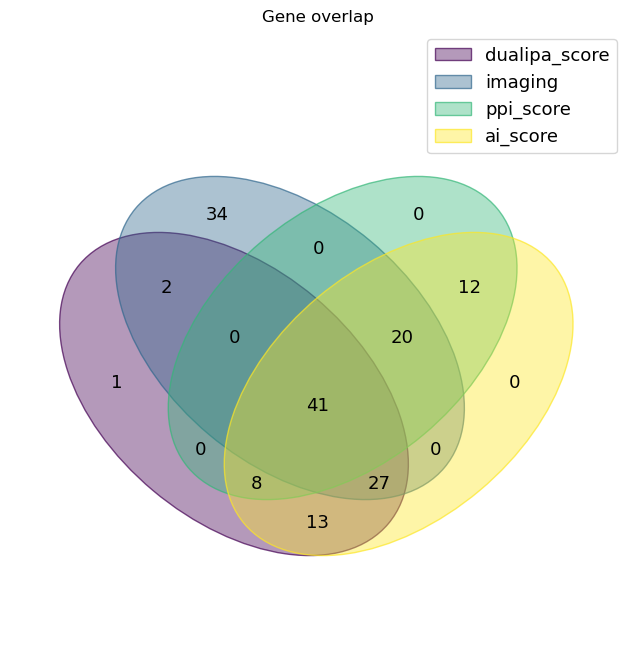

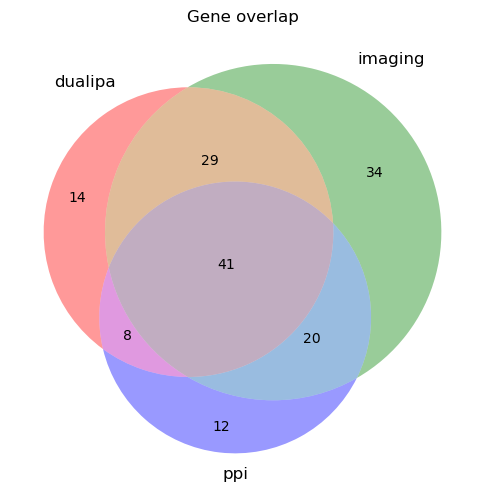

In [36]:
# Compare genes
set_abun = set(scores.filter(pl.col("zscore_log2").is_not_null()).select("symbol").to_series())
set_misloc = set(imaging.select("Gene").to_series())
set_ppi = set(scores.filter(pl.col("ppi_score").is_not_null()).select("symbol").to_series())
set_ai = set(scores.filter(pl.col("ai_score").is_not_null()).select("symbol").to_series())
sets = {
    "dualipa_score": set_abun,
    "imaging": set_misloc,
    "ppi_score": set_ppi,
    "ai_score": set_ai
}

print(f"We profiled this many genes in each assay: {len(set_abun)} for abundance, {len(set_misloc)} for mislocalization, {len(set_ppi)} for ppi, and {len(set_ai)} for AI.")

venn(sets)
plt.title("Gene overlap")
plt.show()

plt.figure(figsize=(6, 6))
venn3([set_abun, set_misloc, set_ppi], ('dualipa', 'imaging', 'ppi'))
plt.title("Gene overlap")
plt.show()

## Compare ClinVar label representation across assays

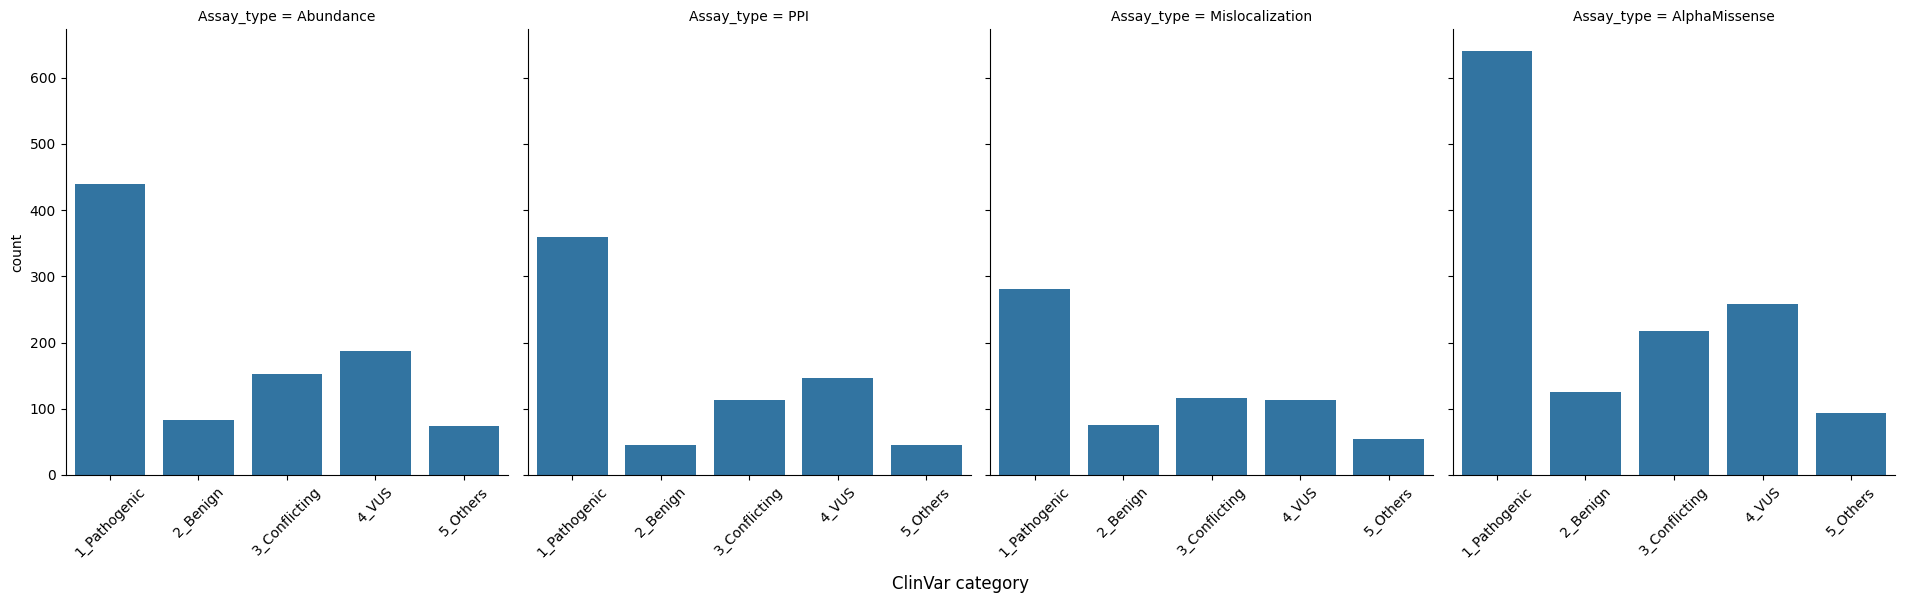

In [9]:
abun = scores.select(["clinvar_clnsig_clean", "abun_score"]).filter(
    ~pl.col("abun_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("Abundance").alias("Assay_type")
    )

ppi = scores.select(["clinvar_clnsig_clean", "ppi_score"]).filter(
    ~pl.col("ppi_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("PPI").alias("Assay_type")
    )

misloc = scores.select(["clinvar_clnsig_clean", "misloc_score"]).filter(
    ~pl.col("misloc_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("Mislocalization").alias("Assay_type")
    )

ai = scores.select(["clinvar_clnsig_clean", "ai_score"]).filter(
    ~pl.col("ai_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("AlphaMissense").alias("Assay_type")
    )

bar_df = pl.concat([abun, ppi, misloc, ai]).to_pandas()

g = sns.catplot(
    bar_df, kind="bar",
    x='clinvar_clnsig_clean', y='count', col="Assay_type",
    height=6, aspect=0.8,
)
g.set_xticklabels(rotation=45)

for ax in g.axes.flatten():
    ax.set_xlabel('')

g.fig.subplots_adjust(bottom=0.2)
g.fig.text(0.5, 0.01, "ClinVar category", ha="center", fontsize=12)
plt.show()

## How many variants are a hit in at least one assay?

In [10]:
# define thresholds
benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
abun_thresh = np.percentile(benign_scores.filter(~pl.col("abun_score").is_null()).select("abun_score").to_numpy(), 90)
misloc_thresh = np.percentile(benign_scores.filter(~pl.col("misloc_score").is_null()).select("misloc_score").to_numpy(), 90)
ppi_thresh = np.percentile(benign_scores.filter(~pl.col("ppi_score").is_null()).select("ppi_score").to_numpy(), 90)
ai_thresh = np.percentile(benign_scores.filter(~pl.col("ai_score").is_null()).select("ai_score").to_numpy(), 90)

scores = scores.with_columns(
    (pl.col("abun_score") > abun_thresh).alias("abun_hit"),
    (pl.col("misloc_score") > misloc_thresh).alias("misloc_hit"),
    (pl.col("ppi_score") > ppi_thresh).alias("ppi_hit"),
    (pl.col("ai_score") > ai_thresh).alias("ai_hit"),
)

scores = scores.with_columns(
    (pl.col("abun_hit").fill_null(False) | pl.col("misloc_hit").fill_null(False) | pl.col("ppi_hit").fill_null(False)).alias("any_hit_no_ai"),
    (pl.col("abun_hit").fill_null(False) | pl.col("misloc_hit").fill_null(False) | pl.col("ppi_hit").fill_null(False) | pl.col("ai_hit").fill_null(False)).alias("any_hit"),
)
scores.write_csv(f"{outputs_dir}/assay_scores.csv")

In [11]:
print(f"Abun: {abun_thresh}, Misloc: {misloc_thresh}, PPI: {ppi_thresh}, AI: {ai_thresh}")

Abun: 2.2254716325827633, Misloc: 0.9220841236645976, PPI: 0.5025974200756175, AI: 0.671775


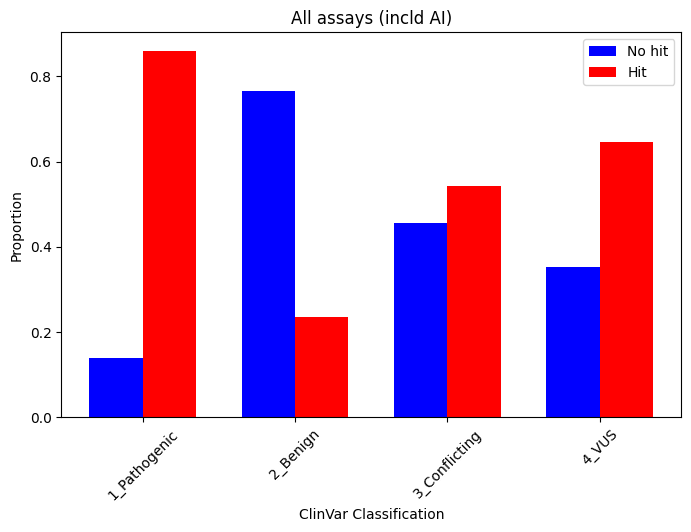

In [93]:
hit_rates = scores.group_by("clinvar_clnsig_clean").agg(
    pl.col("any_hit").value_counts(normalize=True)
).explode("any_hit").unnest("any_hit").pivot(
    values="proportion",
    index="clinvar_clnsig_clean",
    on="any_hit"
).filter(~pl.col("clinvar_clnsig_clean").is_in([None, "5_Others"])).sort(pl.col("clinvar_clnsig_clean"))

df_pd = hit_rates.to_pandas()

# Plot
x = np.arange(len(df_pd))  # Label locations
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, df_pd["false"], width, label="No hit", color="blue")
bars2 = ax.bar(x + width/2, df_pd["true"], width, label="Hit", color="red")

# Labels and formatting
ax.set_xlabel("ClinVar Classification")
ax.set_ylabel("Proportion")
ax.set_xticks(x)
ax.set_xticklabels(df_pd["clinvar_clnsig_clean"], rotation=45)
ax.set_title("All assays (incld AI)")
ax.legend()

plt.show()

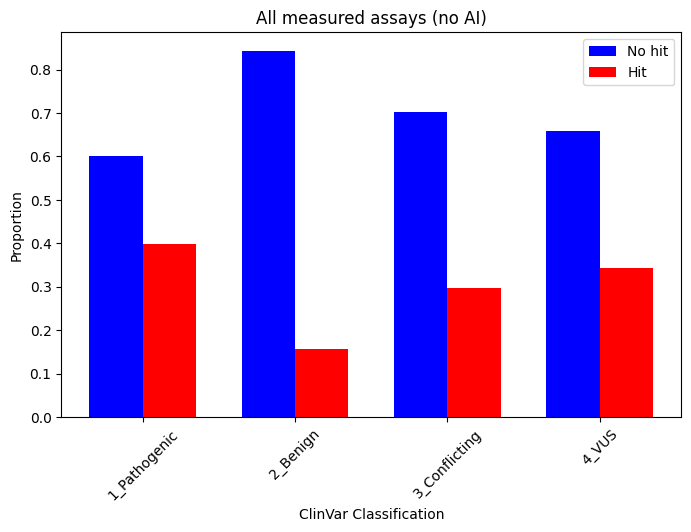

In [94]:
hit_rates = scores.group_by("clinvar_clnsig_clean").agg(
    pl.col("any_hit_no_ai").value_counts(normalize=True)
).explode("any_hit_no_ai").unnest("any_hit_no_ai").pivot(
    values="proportion",
    index="clinvar_clnsig_clean",
    on="any_hit_no_ai"
).filter(~pl.col("clinvar_clnsig_clean").is_in([None, "5_Others"])).sort(pl.col("clinvar_clnsig_clean"))

df_pd = hit_rates.to_pandas()

# Plot
x = np.arange(len(df_pd))  # Label locations
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, df_pd["false"], width, label="No hit", color="blue")
bars2 = ax.bar(x + width/2, df_pd["true"], width, label="Hit", color="red")

# Labels and formatting
ax.set_xlabel("ClinVar Classification")
ax.set_ylabel("Proportion")
ax.set_xticks(x)
ax.set_xticklabels(df_pd["clinvar_clnsig_clean"], rotation=45)
ax.set_title("All measured assays (no AI)")
ax.legend()

plt.show()

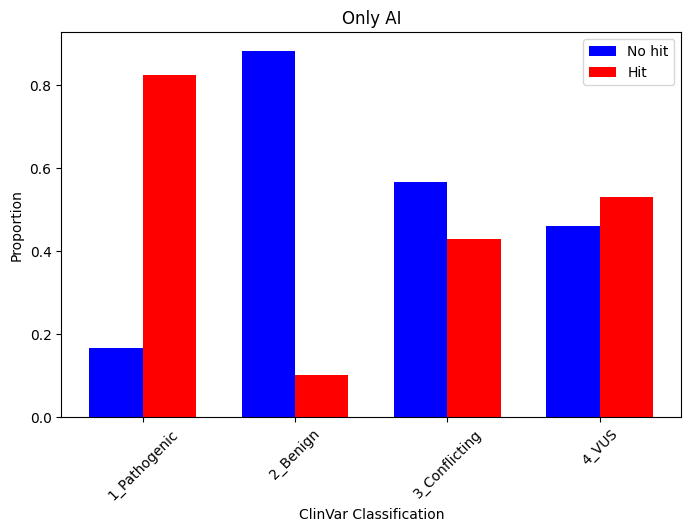

In [95]:
hit_rates = scores.group_by("clinvar_clnsig_clean").agg(
    pl.col("ai_hit").value_counts(normalize=True)
).explode("ai_hit").unnest("ai_hit").pivot(
    values="proportion",
    index="clinvar_clnsig_clean",
    on="ai_hit"
).filter(~pl.col("clinvar_clnsig_clean").is_in([None, "5_Others"])).sort(pl.col("clinvar_clnsig_clean"))

df_pd = hit_rates.to_pandas()

# Plot
x = np.arange(len(df_pd))  # Label locations
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, df_pd["false"], width, label="No hit", color="blue")
bars2 = ax.bar(x + width/2, df_pd["true"], width, label="Hit", color="red")

# Labels and formatting
ax.set_xlabel("ClinVar Classification")
ax.set_ylabel("Proportion")
ax.set_xticks(x)
ax.set_xticklabels(df_pd["clinvar_clnsig_clean"], rotation=45)
ax.set_title("Only AI")
ax.legend()

plt.show()

## What is the overlap of hits across assays?

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2705198571.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2705198571.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2705198571.py:4: FutureWarning: Downc

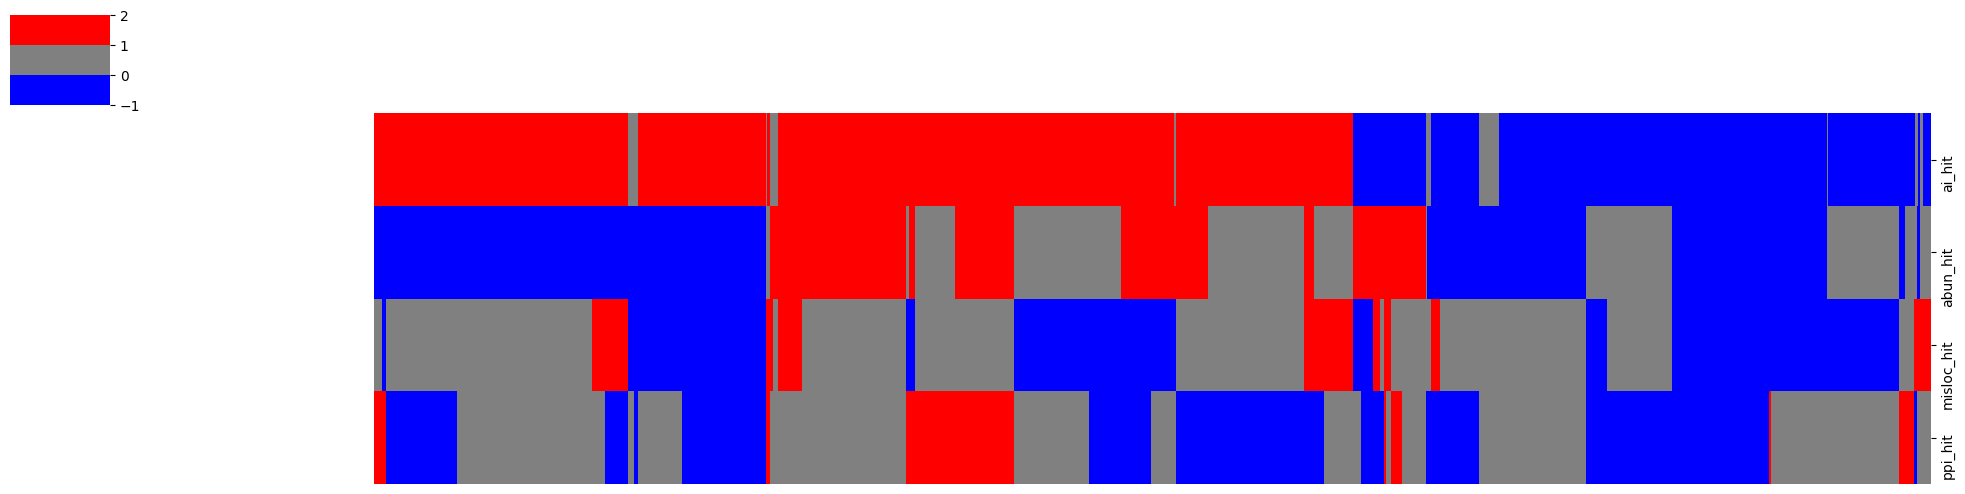

In [70]:
scores_hm = scores.select(["abun_hit", "misloc_hit", "ppi_hit", "ai_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ai_hit'] = scores_hm['ai_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/572254314.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/572254314.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/572254314.py:4: FutureWarning: Downcast

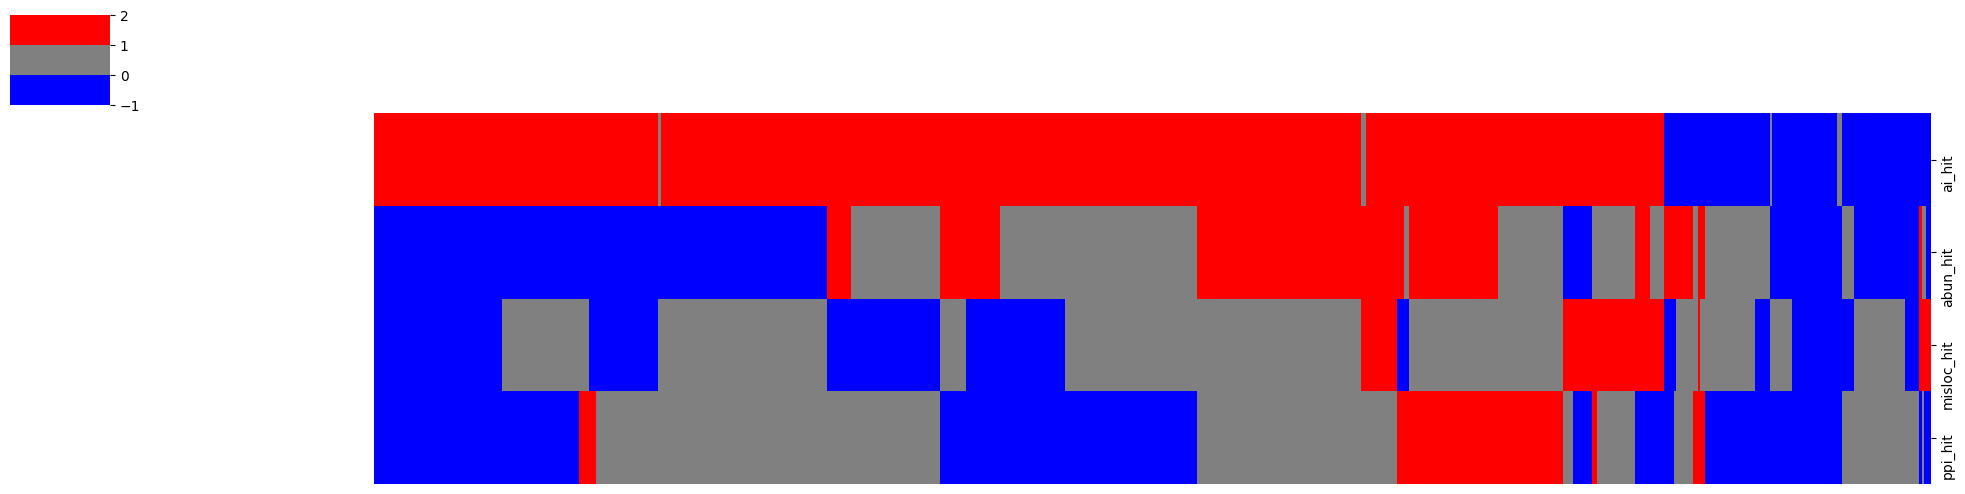

In [71]:
scores_hm = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").select(["abun_hit", "misloc_hit", "ppi_hit", "ai_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ai_hit'] = scores_hm['ai_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2761066996.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2761066996.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2761066996.py:4: FutureWarning: Downc

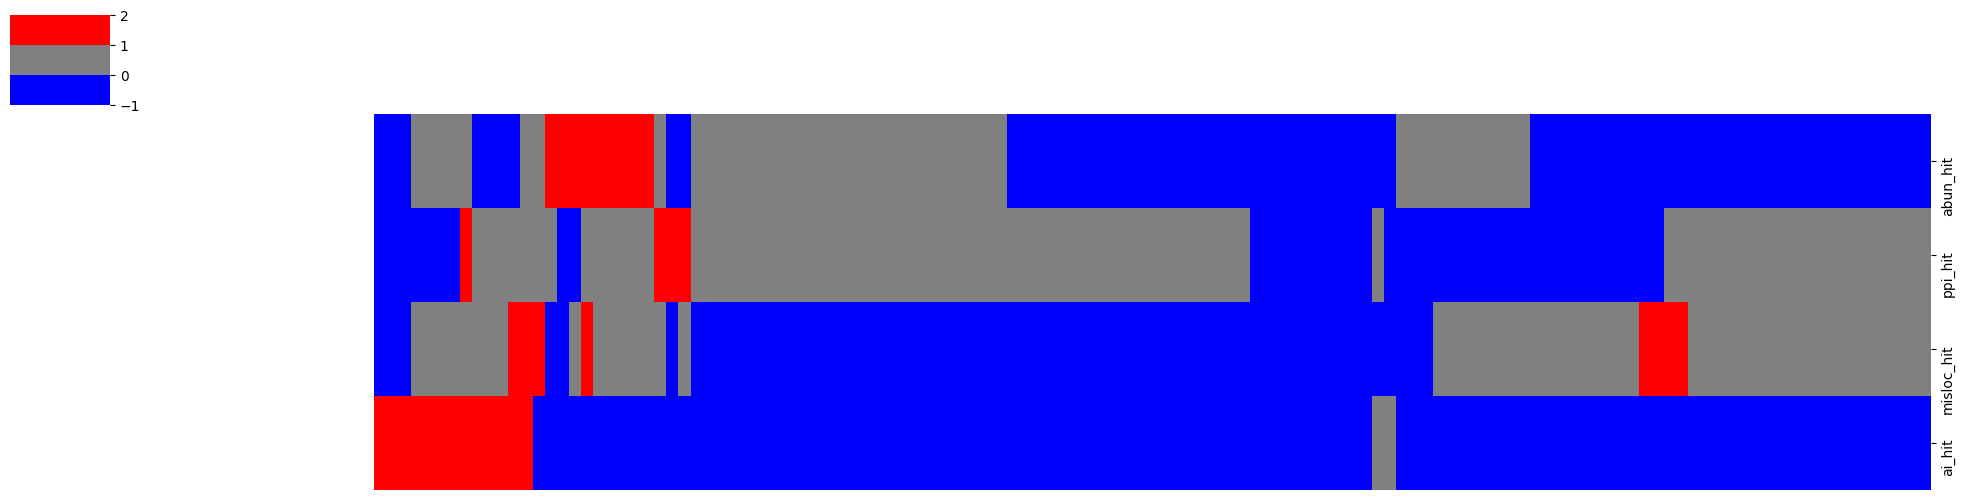

In [72]:
scores_hm = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").select(["abun_hit", "misloc_hit", "ppi_hit", "ai_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ai_hit'] = scores_hm['ai_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

All three: 1
PPI & Misloc: 5
PPI & Abun: 70
Misloc & Abun: 44
Hits in each assay: 320 for abundance, 123 for mislocalization, and 136 for ppi.


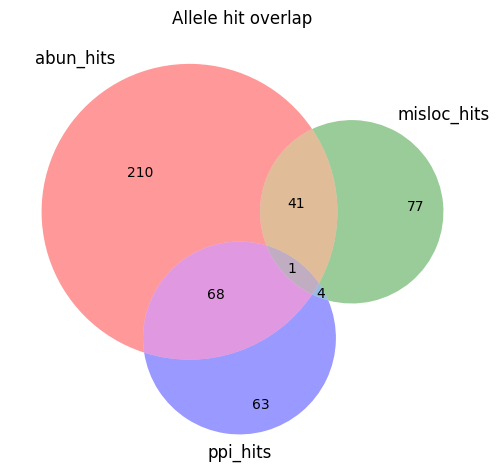

In [73]:
num_ppi_misloc_abun = scores.filter((pl.col("misloc_hit").fill_null(False)) &
                                    (pl.col("ppi_hit").fill_null(False)) &
                                    (pl.col("abun_hit").fill_null(False))).shape[0]

num_ppi_misloc = scores.filter((pl.col("misloc_hit").fill_null(False)) &
                               (pl.col("ppi_hit").fill_null(False)) ).shape[0]

num_ppi_abun = scores.filter((pl.col("abun_hit").fill_null(False)) &
                             (pl.col("ppi_hit").fill_null(False)) ).shape[0]

num_misloc_abun = scores.filter((pl.col("abun_hit").fill_null(False)) &
                                (pl.col("misloc_hit").fill_null(False)) ).shape[0]

print(f"All three: {num_ppi_misloc_abun}")
print(f"PPI & Misloc: {num_ppi_misloc}")
print(f"PPI & Abun: {num_ppi_abun}")
print(f"Misloc & Abun: {num_misloc_abun}")

# Show in Venn Diagram
set_abun = set(scores.filter(pl.col("abun_hit").fill_null(False)).select("allele_0").to_series())
set_misloc = set(scores.filter(pl.col("misloc_hit").fill_null(False)).select("allele_0").to_series())
set_ppi = set(scores.filter(pl.col("ppi_hit").fill_null(False)).select("allele_0").to_series())

print(f"Hits in each assay: {len(set_abun)} for abundance, {len(set_misloc)} for mislocalization, and {len(set_ppi)} for ppi.")

plt.figure(figsize=(6, 6))
venn3([set_abun, set_misloc, set_ppi], ('abun_hits', 'misloc_hits', 'ppi_hits'))
plt.title("Allele hit overlap")
plt.show()

In [74]:
set_abun.intersection(set_ppi, set_misloc)

set_ppi.intersection(set_misloc)

{'FBP1_Pro284Arg',
 'HPRT1_Phe74Leu',
 'KRT5_Gly476Asp',
 'KRT5_Lys404Glu',
 'NMNAT1_Arg237Leu'}

## Output gene lists for analysis

In [15]:
abun_background = scores.filter(~pl.col("abun_hit").is_null()).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/abun_background.csv"
)
abun_hits = scores.filter(~pl.col("abun_hit").is_null()).filter(pl.col("abun_hit")).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/abun_hits.csv"
)

misloc_background = scores.filter(~pl.col("misloc_hit").is_null()).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/misloc_background.csv"
)
misloc_hits = scores.filter(~pl.col("misloc_hit").is_null()).filter(pl.col("misloc_hit")).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/misloc_hits.csv"
)

ppi_background = scores.filter(~pl.col("ppi_hit").is_null()).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/ppi_background.csv"
)
ppi_hits = scores.filter(~pl.col("ppi_hit").is_null()).filter(pl.col("ppi_hit")).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/ppi_hits.csv"
)

We did not find any significant patterns with gene-level enrichment analysis. This is not overly surprising because the lists are very small so we are very underpowered to detect patterns. 